In [3]:
# Importing Libraries
import pandas as pd
from datasets import load_dataset

import matplotlib.pyplot as plt

# Loading the dataset
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()

#data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
import ast
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

df_DS = df[df['job_title_short'] == 'Data Scientist'].copy()

c:\Users\Dell\anaconda3\envs\Best_Room\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
df_DS = df[df['job_title_short'] == 'Data Scientist'].copy()

df_DS['job_posted_month_no'] = df_DS['job_posted_date'].dt.month

df_DS_exploded = df_DS.explode('job_skills')

df_DS_exploded = df_DS.explode('job_skills')

df_DS_pivot = df_DS_exploded.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

df_DS_pivot.loc['Total']=df_DS_pivot.sum()

df_DS_pivot = df_DS_pivot[df_DS_pivot.loc['Total'].sort_values(ascending=False).index]

df_DS_pivot = df_DS_pivot.drop('Total')


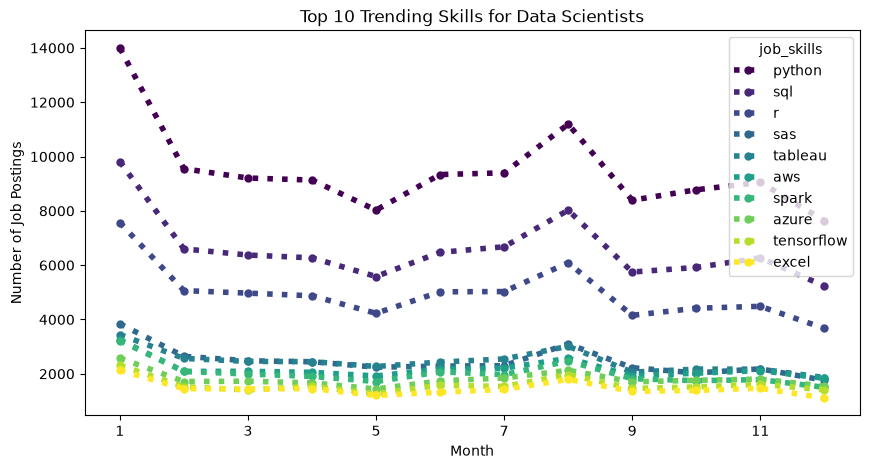

In [5]:
df_DS_pivot.iloc[:, :10].plot(kind='line', 
linewidth=4, 
linestyle= ':', #other options '-', '--', '-.'
colormap= 'viridis',
marker= 'o',
markersize= 5,
figsize= (10,5)
)  
plt.title('Top 10 Trending Skills for Data Scientists') 
plt.xlabel('Month')
plt.ylabel('Number of Job Postings')
plt.show()

In [6]:
df_exploded = df.explode('job_skills')

skills_stats = df_exploded.groupby('job_skills').agg(
    skill_count=('job_skills','count'),
    median_salary = ('salary_year_avg','median')
)

skills_stats = skills_stats.sort_values(by= 'skill_count', ascending= False).head(10)

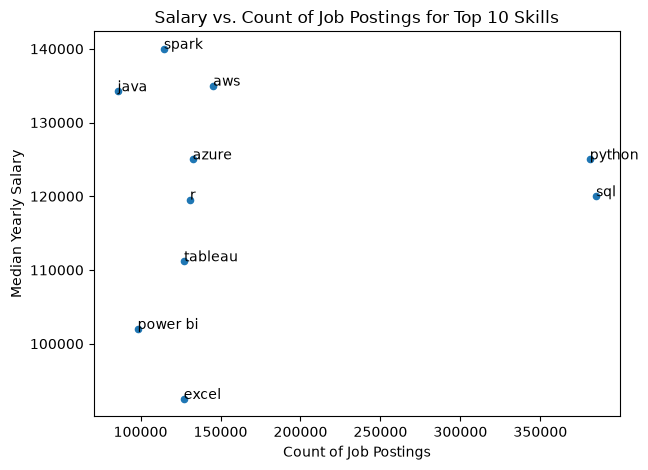

In [7]:
skills_stats.plot(kind= 'scatter', x= 'skill_count', y= 'median_salary')
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()

for i, txt in enumerate(skills_stats.index):
    plt.text(skills_stats['skill_count'].iloc[i], skills_stats['median_salary'].iloc[i], txt)
plt.show()

In [8]:
%pip install adjustText

Note: you may need to restart the kernel to use updated packages.


In [14]:
from adjustText import adjust_text



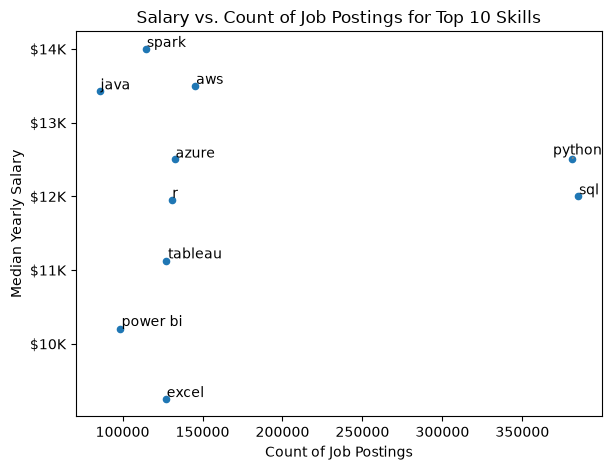

In [17]:
#fig, ax = plt.subplot()

skills_stats.plot(kind= 'scatter', x= 'skill_count', y= 'median_salary')
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()
texts = []
for i, txt in enumerate(skills_stats.index):
    texts.append(plt.text(skills_stats['skill_count'].iloc[i], skills_stats['median_salary'].iloc[i], txt))

adjust_text(texts, arrowprops=dict(arrowstyle="->", color= 'gray', lw= 1))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/10000)}K'))
plt.show()